# Notebook 06: Final Analysis and Conclusions

**Purpose.** Bring together the whole project: the question, the method, the actual results, a direct answer, the limitations, and an independent check that all saved results are valid. All numbers in the tables are read from files saved by earlier notebooks, and the narrative figures were checked against them.

In [1]:
import sys
sys.path.append("..")

import json

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score

from src.data_loader import load_clean_data, load_config, load_raw_data, load_representation, project_path

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 60)

config = load_config()
METRICS_DIR = project_path(config["paths"]["metrics_dir"])
PROFILES_DIR = project_path(config["paths"]["profiles_dir"])
FIGURES_DIR = project_path(config["paths"]["figures_dir"])
PROCESSED_DIR = project_path(config["paths"]["processed_dir"])

## A. Research question

> Can K-Means and Agglomerative Hierarchical Clustering identify meaningful and interpretable user behavior segments in a music streaming platform?

## B. Methodology summary

| Step | What was done |
|---|---|
| **Dataset** | 50,000 synthetic users and 18 columns; no missing values or duplicates; no data dictionary |
| **Feature selection** | Four behavioural features: listening hours, playlists, skips, suggestion rating. Identifiers, dates, demographics and outcome-like columns kept out |
| **Preprocessing** | StandardScaler; no `log1p`, because the features are not meaningfully skewed; no rows removed. Representation B adds one-hot genre and device for comparison |
| **K-Means** | `k` from 2 to 10, `k-means++`, 20 restarts, all users |
| **CAH** | Linkages compared on a 5,000-user sample; Ward then fitted on all users with vector-based `fastcluster`; `k` from 2 to 10 |
| **Evaluation** | Silhouette, Davies-Bouldin, Calinski-Harabasz, interpretability, and stability (ARI) |
| **Reference test** | Same pipeline on 10 column-permuted datasets, which cannot contain joint structure (an addition to the original plan) |
| **Profiling** | Means and medians in original units, evidence for each name, and tests against variables not used in clustering |

## C. Main results

In [2]:
final_comparison = pd.read_csv(METRICS_DIR / "final_model_comparison.csv")
final_comparison.set_index("algorithm").T.round(4)

algorithm,K-Means,Ward (CAH)
k,5.0000,5.0000
silhouette_all_users,0.1858,0.1034
silhouette_10k_subset,0.1844,0.1037
davies_bouldin,1.3209,1.6308
calinski_harabasz,10674.5085,7238.2479
smallest_cluster_share,0.1622,0.1328
largest_cluster_share,0.2294,0.2876
reference_silhouette_mean,0.1852,0.1099
reference_silhouette_min,0.1834,0.1016
reference_silhouette_max,0.1884,0.1219


In [3]:
kmeans_sizes = pd.read_csv(PROFILES_DIR / "kmeans_cluster_sizes.csv")
ward_sizes = pd.read_csv(PROFILES_DIR / "cah_cluster_sizes.csv")
display(pd.concat({"K-Means": kmeans_sizes, "Ward (CAH)": ward_sizes}, axis=1))
display(pd.read_csv(PROFILES_DIR / "segment_name_evidence.csv"))

K-Means                         Ward (CAH)               
             segment  users percent             segment  users percent
0    Light Listeners  11468   22.94  Low-Skip Listeners  14382   28.76
1    Heavy Listeners  11193   22.39   Frequent Skippers  13603   27.21
2  Playlist Builders   9673   19.35    Low-Rating Users   8125   16.25
3  Frequent Skippers   9554   19.11     Light Listeners   7248   14.50
4   Low-Rating Users   8112   16.22   Playlist Builders   6642   13.28

,algorithm,segment,defining_feature,segment_mean,all_users_mean,z_score,second_feature,second_z_score
0,K-Means,Frequent Skippers,avg_skips_per_day,14.28,10.03,1.34,music_suggestion_rating_1_to_5,0.26
1,K-Means,Heavy Listeners,avg_listening_hours_per_week,13.68,9.99,0.93,playlists_created,-0.52
2,K-Means,Light Listeners,avg_listening_hours_per_week,6.02,9.99,-1.00,avg_skips_per_day,-0.45
3,K-Means,Low-Rating Users,music_suggestion_rating_1_to_5,1.83,3.64,-1.63,avg_skips_per_day,-0.07
4,K-Means,Playlist Builders,playlists_created,11.78,8.00,1.33,music_suggestion_rating_1_to_5,0.29
5,Ward (CAH),Frequent Skippers,avg_skips_per_day,13.41,10.03,1.07,avg_listening_hours_per_week,0.30
6,Ward (CAH),Light Listeners,avg_listening_hours_per_week,6.39,9.99,-0.91,playlists_created,-0.81
7,Ward (CAH),Low-Rating Users,music_suggestion_rating_1_to_5,2.11,3.64,-1.38,avg_listening_hours_per_week,-0.46
8,Ward (CAH),Low-Skip Listeners,avg_skips_per_day,7.79,10.03,-0.71,avg_listening_hours_per_week,0.62
9,Ward (CAH),Playlist Builders,playlists_created,11.29,8.00,1.16,music_suggestion_rating_1_to_5,0.53


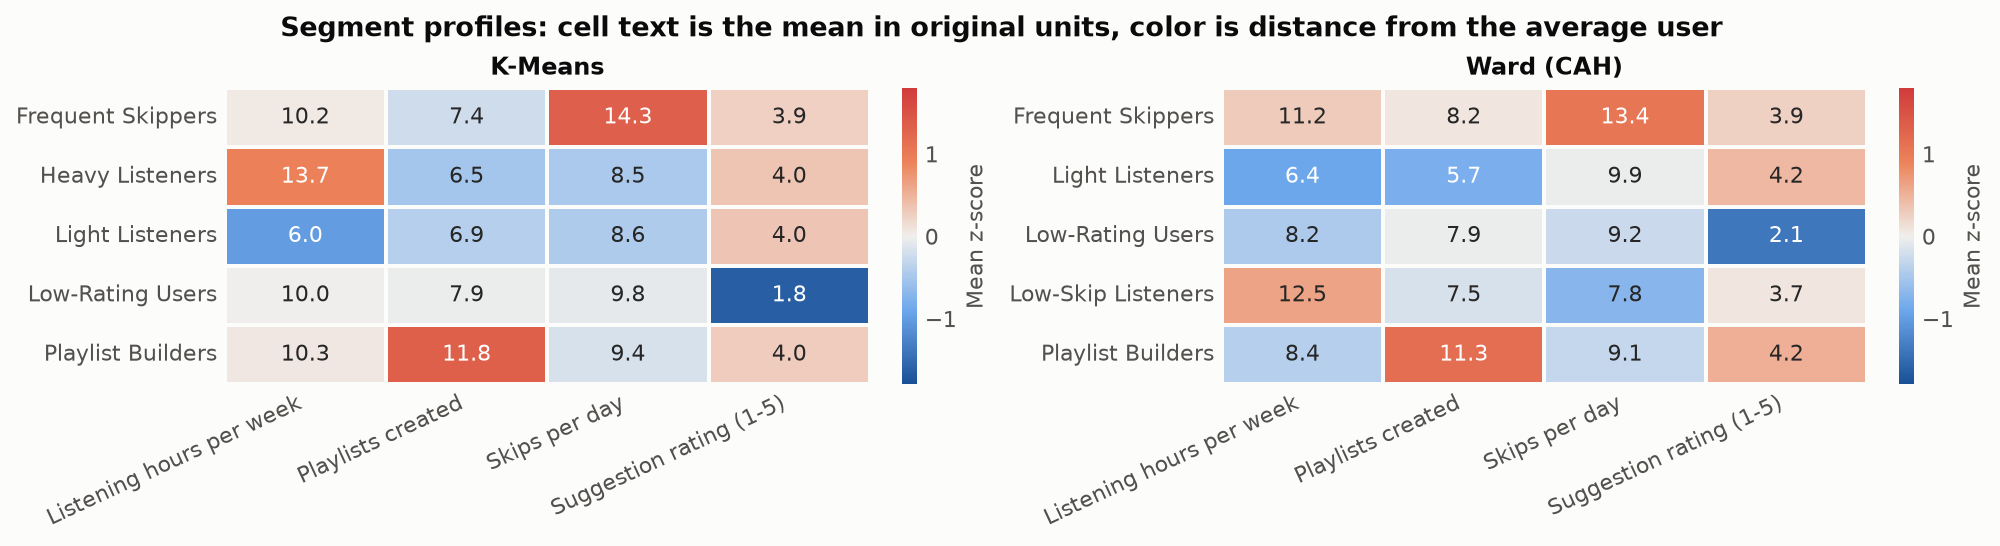

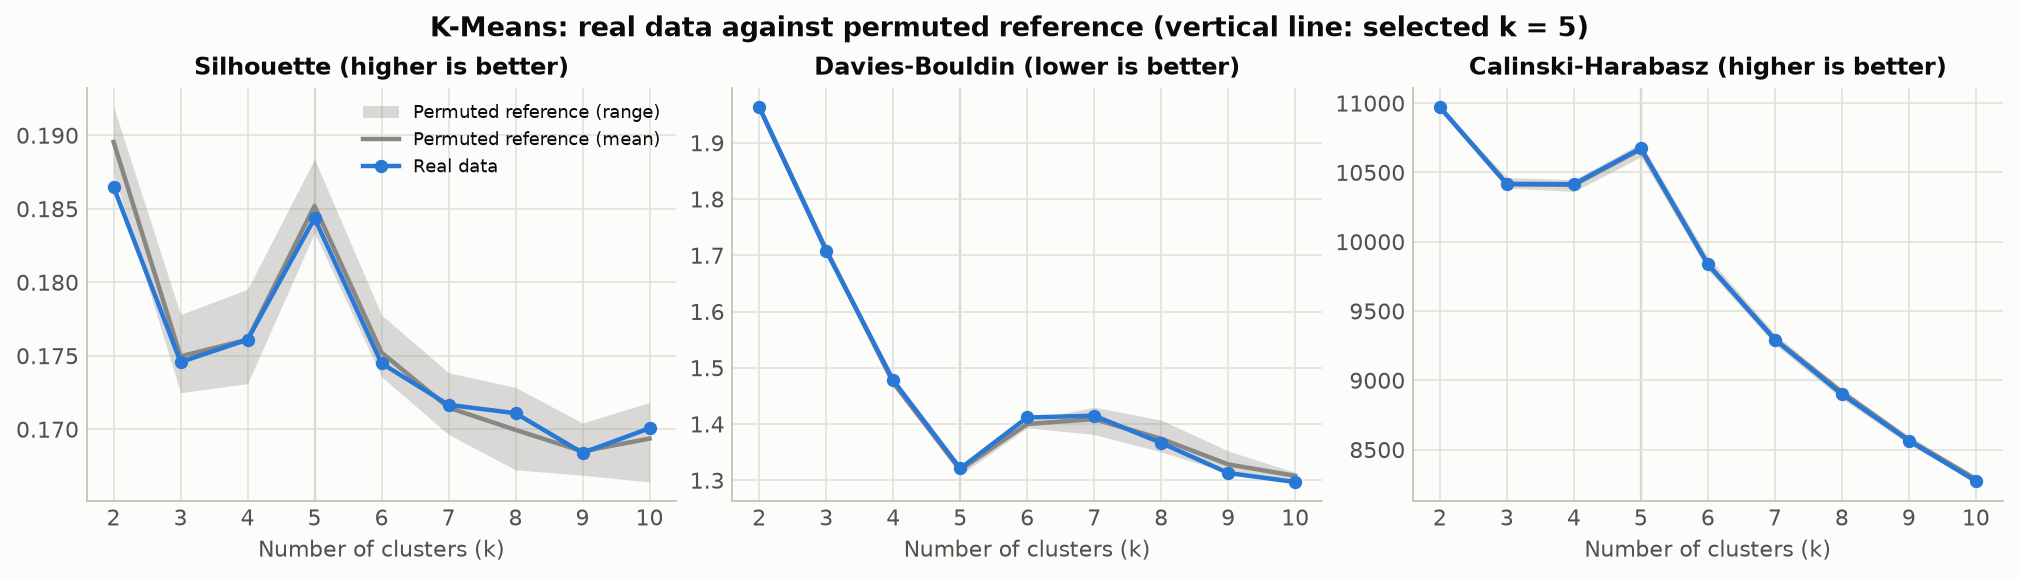

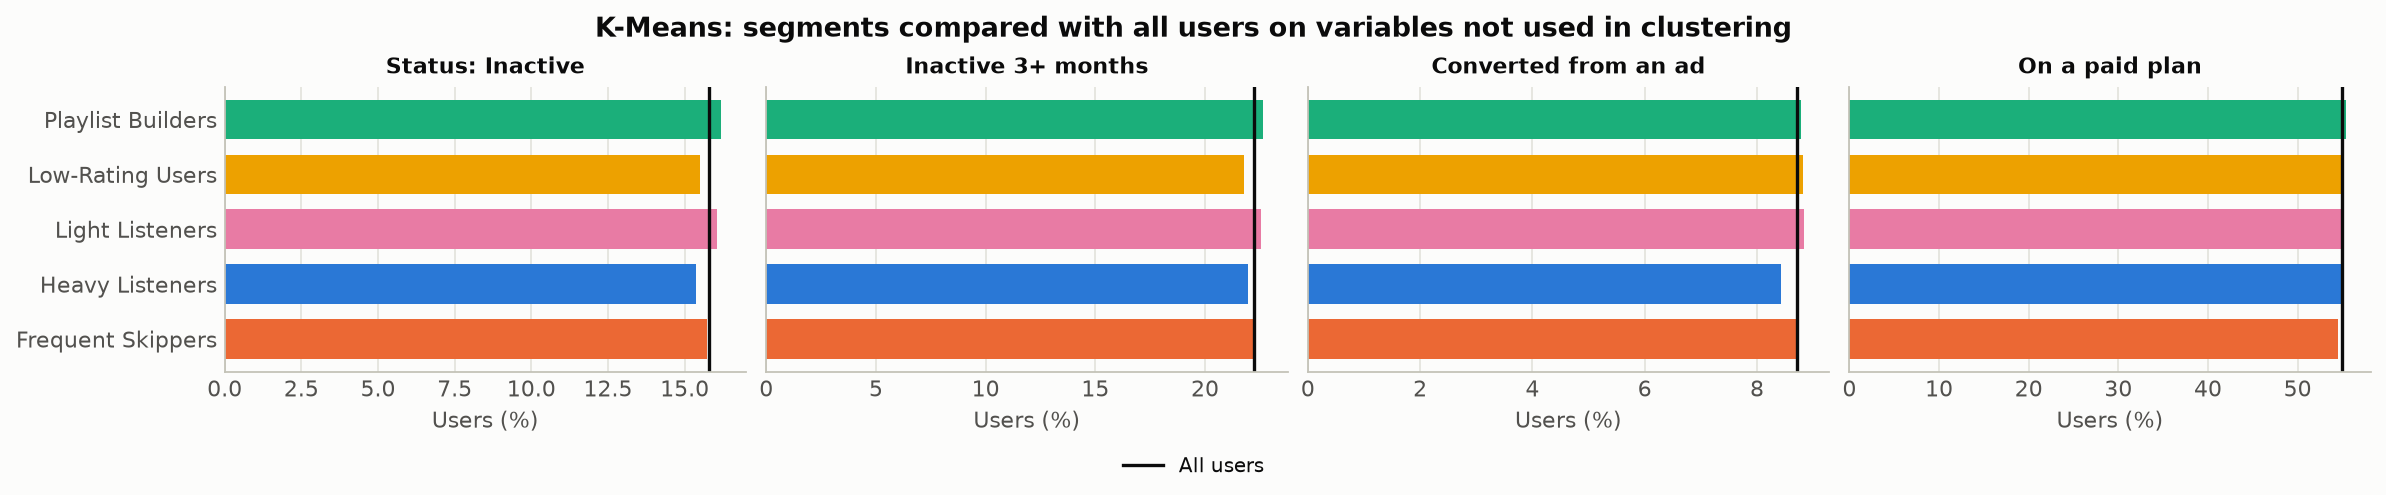

In [4]:
display(Image(FIGURES_DIR / "comparison_profile_heatmaps.png", width=950))
display(Image(FIGURES_DIR / "kmeans_metrics_vs_reference.png", width=950))
display(Image(FIGURES_DIR / "comparison_external_rates_kmeans.png", width=950))

In [5]:
print("Effect sizes against variables not used in clustering:")
associations = pd.read_csv(METRICS_DIR / "external_associations.csv")
display(associations.groupby("algorithm")["effect_size"].agg(["max", "mean"]).round(4))
print("Sensitivity (ARI against the baseline partition):")
sensitivity = pd.read_csv(METRICS_DIR / "sensitivity_analysis.csv")
display(sensitivity.pivot(index="change", columns="algorithm", values="ari_with_baseline").round(3))
print("Subsample stability at k = 5:")
stability = pd.concat([pd.read_csv(METRICS_DIR / "kmeans_subsample_stability.csv"), pd.read_csv(METRICS_DIR / "cah_subsample_stability.csv")])
display(stability[stability["k"] == 5].round(3))

Effect sizes against variables not used in clustering:


,max,mean
algorithm,,
K-Means,0.0145,0.0075
Ward (CAH),0.0139,0.0079


Sensitivity (ARI against the baseline partition):


algorithm,K-Means,Ward (CAH)
change,,
Exclude the zero-listening-hour users,0.926,0.234
Remove the rating feature,0.459,0.156
Representation B (add genre and device),0.963,0.119
RobustScaler instead of StandardScaler,0.462,0.181
k = 4 instead of 5,0.568,0.803
k = 6 instead of 5,0.627,0.890


Subsample stability at k = 5:


,algorithm,dataset,k,mean_ari,min_ari
6,K-Means,Real data,5,0.801,0.698
7,K-Means,Permuted reference,5,0.765,0.476
6,Ward (CAH),Real data,5,0.350,0.153
7,Ward (CAH),Permuted reference,5,0.368,0.201


### Summary of results

| | K-Means | Ward CAH |
|---|---|---|
| Selected `k` | 5 | 5 |
| Silhouette (all users) | 0.186 | 0.103 |
| Davies-Bouldin | 1.321 | 1.631 |
| Calinski-Harabasz | 10,675 | 7,238 |
| Subsample stability (ARI) | 0.801 | 0.350 |

**Segments (all users).**

| K-Means segment | Share | Mainly | Ward segment | Share | Mainly |
|---|---|---|---|---|---|
| Light Listeners | 22.94% | 6.02 hours per week | Low-Skip Listeners | 28.76% | 7.79 skips per day, 12.46 hours |
| Heavy Listeners | 22.39% | 13.68 hours per week | Frequent Skippers | 27.21% | 13.41 skips per day |
| Playlist Builders | 19.35% | 11.78 playlists | Low-Rating Users | 16.25% | Rating 2.11 |
| Frequent Skippers | 19.11% | 14.28 skips per day | Light Listeners | 14.50% | 6.39 hours, 5.71 playlists |
| Low-Rating Users | 16.22% | Rating 1.83 | Playlist Builders | 13.28% | 11.29 playlists |

Overall averages: 9.99 hours per week, 8.00 playlists, 10.03 skips per day, rating 3.64.

**Differences between the algorithms.** K-Means scores better, gives more balanced segments, and is more repeatable. The two agree only moderately (ARI 0.306). Ward has a Low-Skip Listeners segment where K-Means has Heavy Listeners, and its Frequent Skippers segment is barely separated (45.8% of users have a negative silhouette).

**Evidence on natural structure.**

- The largest correlation between behavioural and other numeric variables, excluding the inactivity flag, is 0.008.
- Of 54 comparisons of real against permuted data, 46 fall inside the reference range, 2 are better than all references and 6 are worse, which is what chance would suggest.
- The largest association between any segment solution and any external variable is Cramér's V = 0.0145; none of the 26 tests is significant.

## D. Answering the research question

**Partly. Both algorithms produce interpretable segments, but the evidence does not show that those segments are natural or meaningful groups of users in this dataset.**

- **Interpretable: yes.** Both produce five segments that can be described in plain terms, such as Heavy Listeners or Frequent Skippers, using original units. K-Means is clearer, and it is the better choice if a descriptive segmentation is needed.
- **Natural: no evidence.** Silhouette values are weak (below 0.2). Metrics, stability and even the dendrogram gap are matched by data with no joint structure. The features are effectively independent, so the population forms one continuous cloud, and the algorithms slice it because they are designed to return clusters regardless.
- **Meaningful beyond the inputs: no.** Segments are unrelated to inactivity, status, plan, conversion, age, tenure, country and preferences. They provide no way to predict or explain any of these.

**The practical takeaway.** These segments are **useful summaries of users' positions on four features, similar to labelling users as high or low on a scale**. They are not discovered user types. A result like this is still a success for the method: because it included a structureless reference, the project avoided presenting an artifact as a discovery.

## E. Limitations

- **Synthetic data.** The variables appear to have been generated largely independently, so conclusions apply to this dataset and **not to real music streaming users or to any real platform**. Real users would be expected to show correlations that this file lacks.
- **Potential artificial patterns.** Implausible combinations were found, such as Free users marked as converted. Near-uniform categories and Poisson-like counts also point to simulation.
- **No ground truth.** There are no true segment labels, so accuracy cannot be measured.
- **Limits of internal metrics.** They favour compact, round clusters and can reward useless partitions: single linkage had the highest Silhouette of all (0.419 at `k = 2`) with one cluster at 99.98%.
- **Limits of the reference test.** Permutation tests only for structure *between* features. Ten datasets give a range and not a precise p-value, and results across `k` are related.
- **Sensitivity to features and scaling.** Replacing StandardScaler with RobustScaler, or removing the rating, changes the partition substantially (K-Means ARI about 0.46; Ward below 0.2).
- **Treating the rating as numeric** assumes equal gaps between ordinal levels.
- **PCA visualization** shows only 50.3% of the variance, so overlaps in the 2D plots can be misleading.
- **Computational limits of CAH.** The standard method needs 10 GB for the distance matrix, and the vector shortcut only exists for some linkages, so the linkages were compared on a 5,000-user sample, and average and complete linkage were not run on all users.
- **Undocumented columns.** Without a data dictionary, meanings and the tenure snapshot date are assumptions. Silhouette during model selection also used a 10,000-user subset, although final values were confirmed on all users.

## F. Future work

1. **Validate on real user data.** This is the most important next step. Applying the same pipeline, including the reference test, to real behaviour would show whether natural segments exist.
2. **Test formally for the number of groups.** Add a method that can conclude `k = 1`, such as a Gaussian mixture model compared by BIC. K-Means and CAH cannot return "no clusters", which is the core limitation found here.
3. **Explore other feature representations.** Examples include session-level or genre-mix features, which might carry real dependence. For mixed data, Gower distance would avoid some problems of one-hot encoding.
4. **Compare with density-based clustering** such as HDBSCAN, which can decide that points belong to no cluster.
5. **Study segment evolution over time,** if temporal data becomes available. Users who move between segments may be more informative than a snapshot.
6. **Use a data dictionary.** Confirming column definitions would resolve the cross-column oddities and make it possible to test questions about churn correctly.

## G. Reproducibility and validity checks

These checks recompute key results from saved files, independently of the earlier notebooks. An `AssertionError` here would stop the notebook, so reaching the final message means that all checks passed.

In [6]:
raw = load_raw_data(config)
users = load_clean_data(config)
X_a = load_representation(config, "a")
X_b = load_representation(config, "b")
assignments = pd.read_csv(PROFILES_DIR / "final_segment_assignments.csv")

# 1. Preprocessing is consistent with the raw data.
assert len(raw) == len(users) == len(X_a) == len(X_b) == 50000
assert (raw["user_id"] == users["user_id"]).all() and (users["user_id"] == X_a.index).all()
for feature in config["columns"]["representation_a_numeric"]:
    recomputed = (raw[feature] - raw[feature].mean()) / raw[feature].std(ddof=0)
    assert np.allclose(recomputed, X_a[feature]), feature

# 2. No identifier or outcome-related column reached the clustering inputs.
forbidden = config["columns"]["outcome_related"] + ["user_id", "signup_date", "subscription_type", "ad_interaction", "age", "country"]
for matrix in (X_a, X_b):
    assert not [column for column in matrix.columns for name in forbidden if column == name or column.startswith(f"{name}_")]

# 3. Labels belong to the right users, and cover everyone.
assert (assignments["user_id"] == users["user_id"]).all() and assignments["user_id"].is_unique
assert assignments[["kmeans_label", "ward_label"]].notna().all().all()
assert assignments["kmeans_label"].nunique() == config["kmeans"]["selected_k"]
assert assignments["ward_label"].nunique() == config["hierarchical"]["selected_k"]

# 4. Each label maps to exactly one segment name.
for label_column, name_column in [("kmeans_label", "kmeans_segment"), ("ward_label", "ward_segment")]:
    assert assignments.groupby(label_column)[name_column].nunique().eq(1).all()

# 5. Saved sizes match the labels.
for sizes, column in [(kmeans_sizes, "kmeans_segment"), (ward_sizes, "ward_segment")]:
    assert sizes.set_index("segment")["users"].sort_index().equals(assignments[column].value_counts().sort_index().rename("users"))
    assert sizes["users"].sum() == 50000

# 6. Saved metrics can be recomputed from labels and features.
for algorithm, label_column in [("K-Means", "kmeans_label"), ("Ward (CAH)", "ward_label")]:
    row = final_comparison.set_index("algorithm").loc[algorithm]
    assert np.isclose(davies_bouldin_score(X_a, assignments[label_column]), row["davies_bouldin"])
    assert np.isclose(calinski_harabasz_score(X_a, assignments[label_column]), row["calinski_harabasz"])

# 7. Metric bounds and saved tables make sense.
assert final_comparison["silhouette_all_users"].between(-1, 1).all()
for csv_path in list(METRICS_DIR.glob("*.csv")) + list(PROFILES_DIR.glob("*.csv")):
    assert len(pd.read_csv(csv_path)) > 0, csv_path
for json_path in list(METRICS_DIR.glob("*.json")) + list(PROCESSED_DIR.glob("*.json")):
    json.loads(json_path.read_text(encoding="utf-8"))

# 8. Every figure is a non-empty PNG.
figures = sorted(FIGURES_DIR.glob("*.png"))
assert figures and all(path.stat().st_size > 5000 and path.read_bytes()[:4] == b"\x89PNG" for path in figures)

print(f"All checks passed: {len(figures)} figures, {len(list(METRICS_DIR.glob('*.csv')))} metric tables, {len(list(PROFILES_DIR.glob('*.csv')))} profile tables.")

All checks passed: 27 figures, 27 metric tables, 25 profile tables.


## H. Final conclusion

The complete workflow ran from raw data to validated results, and all saved files passed independent checks. K-Means with `k = 5` provides the clearer and more repeatable description, but **this dataset does not contain evidence of natural behavioural groups**. The most valuable lesson for practice is that a clustering algorithm will always return clusters, so results should be compared to a structureless reference before they are presented as discoveries.